# Task 2 — Autoformer


In [23]:
from pathlib import Path
import copy
import json
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

torch.set_float32_matmul_precision("high")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
usemixedprecision = False

predictionlength = 168
validationblocks = 5
screeningvalidationblocks = 3
screeningseed = 17
finalseeds = [17, 29, 43]
screeningtrainingstride = 4
finaltrainingstride = 2
screeningmaxepochs = 6
screeningpatience = 2
finalmaxepochs = 10
finalpatience = 3
batchsize = 32
learningrate = 1e-4
weightdecay = 0.0
gradientclip = 1.0

resultsdirectory = Path("task2_results")
resultsdirectory.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Mixed precision:", usemixedprecision)

Device: cuda
Mixed precision: False


In [24]:
def findassignmentfile(candidatenames):
    searchroots = [Path.cwd(), Path.cwd().parent, Path("/kaggle/working")]
    foundpaths = []
    for searchroot in searchroots:
        if not searchroot.exists():
            continue
        for candidatename in candidatenames:
            directpath = searchroot / candidatename
            if directpath.exists():
                foundpaths.append(directpath)
            foundpaths.extend(searchroot.glob(f"**/{candidatename}"))
    uniquepaths = []
    seenpaths = set()
    for foundpath in foundpaths:
        resolvedpath = foundpath.resolve()
        if resolvedpath not in seenpaths:
            uniquepaths.append(foundpath)
            seenpaths.add(resolvedpath)
    if not uniquepaths:
        raise FileNotFoundError(f"Could not find any of: {candidatenames}")
    uniquepaths.sort(key=lambda filepath: len(str(filepath)))
    return uniquepaths[0]

trainingfilepath = findassignmentfile(["student train.csv", "student_train.csv"])
testingfilepath = findassignmentfile(["student test.csv", "student_test.csv"])
externalfilepath = findassignmentfile(["optional external data.csv", "optional_external_data.csv"])

trainingframe = pd.read_csv(trainingfilepath)
testingframe = pd.read_csv(testingfilepath)
externalframe = pd.read_csv(externalfilepath)

def normalisecolumnname(columnname):
    return str(columnname).strip().lower().replace(" ", "_")

trainingframe.columns = [normalisecolumnname(columnname) for columnname in trainingframe.columns]
testingframe.columns = [normalisecolumnname(columnname) for columnname in testingframe.columns]
externalframe.columns = [normalisecolumnname(columnname) for columnname in externalframe.columns]

targetcolumn = "value"
timecolumn = "time_idx"

if targetcolumn not in trainingframe.columns:
    raise ValueError(f"Expected '{targetcolumn}' in training data, found {trainingframe.columns.tolist()}")

if timecolumn not in trainingframe.columns or timecolumn not in testingframe.columns or timecolumn not in externalframe.columns:
    raise ValueError("Expected time_idx in all three files")

externalcolumns = [columnname for columnname in externalframe.columns if columnname != timecolumn]

targetvalues = trainingframe[targetcolumn].to_numpy(dtype=np.float32)
trainingtimeindices = trainingframe[timecolumn].to_numpy()
testingtimeindices = testingframe[timecolumn].to_numpy()
externalvalues = externalframe[externalcolumns].to_numpy(dtype=np.float32)

if len(targetvalues) != 43656:
    raise ValueError(f"Expected 43656 training rows, found {len(targetvalues)}")

if len(testingframe) != predictionlength:
    raise ValueError(f"Expected {predictionlength} test rows, found {len(testingframe)}")

if len(externalframe) < len(targetvalues) + predictionlength:
    raise ValueError("Optional external data does not cover the complete forecast horizon")

if np.isnan(targetvalues).any():
    raise ValueError("Training target contains missing values")

if np.isnan(externalvalues).any():
    raise ValueError("External data contains missing values")

print("Training file:", trainingfilepath)
print("Testing file:", testingfilepath)
print("External file:", externalfilepath)
print("Training rows:", len(trainingframe))
print("Test rows:", len(testingframe))
print("External rows:", len(externalframe))
print("External columns:", externalcolumns)

Training file: /kaggle/input/datasets/kangerz22/studenttest/student_train.csv
Testing file: /kaggle/input/datasets/kangerz22/studenttest/student_test.csv
External file: /kaggle/input/datasets/kangerz22/studenttest/optional_external_data.csv
Training rows: 43656
Test rows: 168
External rows: 43824
External columns: ['feature_a', 'feature_b', 'feature_c', 'feature_d', 'feature_e', 'feature_f', 'feature_g', 'feature_h', 'feature_i', 'feature_j']


## EDA (Data Analysis)


,autocorrelation_lag,autocorrelation,periodogram_period,periodogram_power
0,1,0.9665,333.3333,6.128933e+09
1,2,0.9279,171.4286,4.334456e+09
2,3,0.8876,250.0000,3.523692e+09
3,4,0.8483,130.4348,3.035573e+09
4,5,0.8110,428.5714,2.539238e+09
5,6,0.7754,400.0000,2.244826e+09
6,7,0.7419,1200.0000,2.140531e+09
7,8,0.7107,133.3333,2.067568e+09
8,9,0.6843,2000.0000,1.768852e+09
9,10,0.6589,461.5385,1.678371e+09


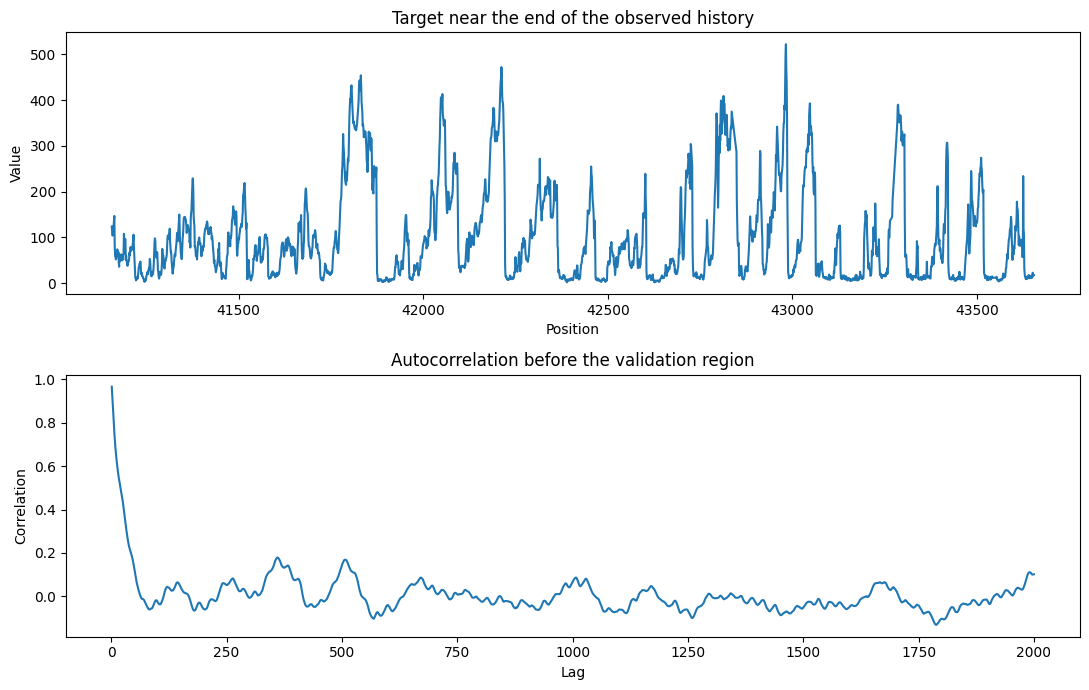

In [25]:
validationstart = len(targetvalues) - validationblocks * predictionlength
validationorigins = np.arange(validationstart, len(targetvalues), predictionlength, dtype=np.int64)

diagnosticlength = min(6000, validationstart)
diagnosticsignal = targetvalues[validationstart - diagnosticlength:validationstart].astype(np.float64)
centeredsignal = diagnosticsignal - diagnosticsignal.mean()
fftlength = 1 << int(np.ceil(np.log2(2 * len(centeredsignal))))
signalspectrum = np.fft.rfft(centeredsignal, n=fftlength)
autocovariance = np.fft.irfft(signalspectrum * np.conj(signalspectrum), n=fftlength)[:len(centeredsignal)]
normalisationcounts = np.arange(len(centeredsignal), 0, -1)
autocorrelation = autocovariance / normalisationcounts
autocorrelation = autocorrelation / max(autocorrelation[0], 1e-12)

maximumdiagnosticlag = min(2000, len(autocorrelation) - 1)
candidateautocorrelation = autocorrelation[1:maximumdiagnosticlag + 1]
strongestlagindices = np.argsort(candidateautocorrelation)[-20:][::-1] + 1

frequencyvalues = np.fft.rfftfreq(len(centeredsignal))
periodogramvalues = np.abs(np.fft.rfft(centeredsignal)) ** 2
validfrequencies = frequencyvalues > 0
periodogramperiods = 1.0 / frequencyvalues[validfrequencies]
validperiodogrampowers = periodogramvalues[validfrequencies]
reasonableperiods = (periodogramperiods >= 4) & (periodogramperiods <= 2000)
selectedperiods = periodogramperiods[reasonableperiods]
selectedpowers = validperiodogrampowers[reasonableperiods]
strongestperiodindices = np.argsort(selectedpowers)[-20:][::-1]

diagnosticstable = pd.DataFrame({
    "autocorrelation_lag": strongestlagindices[:10],
    "autocorrelation": autocorrelation[strongestlagindices[:10]],
    "periodogram_period": selectedperiods[strongestperiodindices[:10]],
    "periodogram_power": selectedpowers[strongestperiodindices[:10]]
})

display(diagnosticstable.round(4))

figure, axes = plt.subplots(2, 1, figsize=(11, 7))
plotstart = max(0, len(targetvalues) - 2500)
axes[0].plot(np.arange(plotstart, len(targetvalues)), targetvalues[plotstart:])
axes[0].set_title("Target near the end of the observed history")
axes[0].set_xlabel("Position")
axes[0].set_ylabel("Value")
axes[1].plot(np.arange(1, maximumdiagnosticlag + 1), candidateautocorrelation)
axes[1].set_title("Autocorrelation before the validation region")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Correlation")
figure.tight_layout()
figure.savefig(resultsdirectory / "Q2_Figure_1_data_diagnostics.pdf", bbox_inches="tight")
plt.show()

## Scaling and forecast-window construction

Two target normalisation schemes are compared programmatically: global training-only standardisation and window-relative standardisation. Continuous external variables are standardised with training-only statistics; binary indicator columns remain in their original 0/1 form.

In [26]:
def detectbinarycolumns(values):
    binarymask = []
    for columnindex in range(values.shape[1]):
        uniquevalues = np.unique(values[:, columnindex])
        binarymask.append(np.all(np.isin(uniquevalues, [0.0, 1.0])))
    return np.array(binarymask, dtype=bool)

def fitexternalscaler(values):
    binarymask = detectbinarycolumns(values)
    means = values.mean(axis=0).astype(np.float32)
    standarddeviations = values.std(axis=0).astype(np.float32)
    standarddeviations = np.where(standarddeviations < 1e-6, 1.0, standarddeviations)
    means = np.where(binarymask, 0.0, means)
    standarddeviations = np.where(binarymask, 1.0, standarddeviations)
    return {
        "means": means,
        "standarddeviations": standarddeviations,
        "binarymask": binarymask
    }

def transformexternalvalues(values, scaler):
    return ((values - scaler["means"]) / scaler["standarddeviations"]).astype(np.float32)

def targetstatistics(contextvalues, normalisationmode, globalmean, globalstandarddeviation):
    if normalisationmode == "window":
        location = float(contextvalues.mean())
        scale = float(contextvalues.std())
    elif normalisationmode == "global":
        location = float(globalmean)
        scale = float(globalstandarddeviation)
    else:
        raise ValueError(f"Unknown normalisation mode: {normalisationmode}")
    if scale < 1e-6:
        scale = 1.0
    return location, scale

class ForecastWindowDataset(Dataset):
    def __init__(
        self,
        targetarray,
        externalarray,
        origins,
        sequencelength,
        predictionlength,
        normalisationmode,
        globalmean,
        globalstandarddeviation
    ):
        self.targetarray = targetarray
        self.externalarray = externalarray
        self.origins = np.asarray(origins, dtype=np.int64)
        self.sequencelength = int(sequencelength)
        self.predictionlength = int(predictionlength)
        self.normalisationmode = normalisationmode
        self.globalmean = float(globalmean)
        self.globalstandarddeviation = float(globalstandarddeviation)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, itemindex):
        origin = int(self.origins[itemindex])
        contextvalues = self.targetarray[origin - self.sequencelength:origin].astype(np.float32)
        futurevalues = self.targetarray[origin:origin + self.predictionlength].astype(np.float32)
        location, scale = targetstatistics(
            contextvalues,
            self.normalisationmode,
            self.globalmean,
            self.globalstandarddeviation
        )
        normalisedcontext = ((contextvalues - location) / scale).astype(np.float32)
        normalisedfuture = ((futurevalues - location) / scale).astype(np.float32)

        if self.externalarray is None:
            externalhistory = np.zeros((self.sequencelength, 0), dtype=np.float32)
            externalfuture = np.zeros((self.predictionlength, 0), dtype=np.float32)
        else:
            externalhistory = self.externalarray[origin - self.sequencelength:origin].astype(np.float32)
            externalfuture = self.externalarray[origin:origin + self.predictionlength].astype(np.float32)

        return {
            "encodercontext": torch.from_numpy(normalisedcontext[:, None]),
            "externalhistory": torch.from_numpy(externalhistory),
            "externalfuture": torch.from_numpy(externalfuture),
            "targetfuture": torch.from_numpy(normalisedfuture[:, None]),
            "originalfuture": torch.from_numpy(futurevalues[:, None]),
            "location": torch.tensor(location, dtype=torch.float32),
            "scale": torch.tensor(scale, dtype=torch.float32),
            "origin": torch.tensor(origin, dtype=torch.long)
        }

In [27]:
class SeriesDecomposition(nn.Module):
    def __init__(self, kernelsize):
        super().__init__()
        if kernelsize % 2 == 0:
            raise ValueError("Moving-average kernel size must be odd")
        self.kernelsize = int(kernelsize)

    def forward(self, values):
        paddingamount = self.kernelsize // 2
        channelmajor = values.transpose(1, 2)
        paddedvalues = F.pad(channelmajor, (paddingamount, paddingamount), mode="replicate")
        trendvalues = F.avg_pool1d(paddedvalues, kernel_size=self.kernelsize, stride=1)
        trendvalues = trendvalues.transpose(1, 2)
        seasonalvalues = values - trendvalues
        return seasonalvalues, trendvalues

class AutoCorrelation(nn.Module):
    def __init__(self, factor, dropout):
        super().__init__()
        self.factor = float(factor)
        self.dropout = nn.Dropout(dropout)
        self.lastselecteddelays = None

    def resizekeyvalues(self, values, targetlength):
        currentlength = values.shape[1]
        if currentlength == targetlength:
            return values
        if currentlength > targetlength:
            return values[:, -targetlength:, :, :]
        paddinglength = targetlength - currentlength
        padding = torch.zeros(
            values.shape[0],
            paddinglength,
            values.shape[2],
            values.shape[3],
            device=values.device,
            dtype=values.dtype
        )
        return torch.cat([padding, values], dim=1)

    def forward(self, queries, keys, values):
        querylength = queries.shape[1]
        keys = self.resizekeyvalues(keys, querylength)
        values = self.resizekeyvalues(values, querylength)

        querymajor = queries.permute(0, 2, 3, 1)
        keymajor = keys.permute(0, 2, 3, 1)
        valuemajor = values.permute(0, 2, 3, 1)

        queryspectrum = torch.fft.rfft(querymajor, dim=-1)
        keyspectrum = torch.fft.rfft(keymajor, dim=-1)
        correlations = torch.fft.irfft(
            queryspectrum * torch.conj(keyspectrum),
            n=querylength,
            dim=-1
        )

        delayscores = correlations.mean(dim=(1, 2))
        selectedcount = max(1, min(querylength, int(self.factor * math.log(querylength))))
        selectedscores, selecteddelays = torch.topk(delayscores, selectedcount, dim=-1)
        selectedweights = torch.softmax(selectedscores, dim=-1)
        selectedweights = self.dropout(selectedweights)

        batchsize, headcount, headwidth, sequencelength = valuemajor.shape
        timepositions = torch.arange(sequencelength, device=values.device)
        sourcepositions = (
            timepositions.reshape(1, 1, sequencelength)
            - selecteddelays.reshape(batchsize, selectedcount, 1)
        ) % sequencelength

        expandedvalues = valuemajor.unsqueeze(1).expand(
            batchsize,
            selectedcount,
            headcount,
            headwidth,
            sequencelength
        )
        gatherpositions = sourcepositions.reshape(
            batchsize,
            selectedcount,
            1,
            1,
            sequencelength
        ).expand(
            batchsize,
            selectedcount,
            headcount,
            headwidth,
            sequencelength
        )
        shiftedvalues = torch.gather(expandedvalues, dim=-1, index=gatherpositions)
        weightedvalues = shiftedvalues * selectedweights.reshape(
            batchsize,
            selectedcount,
            1,
            1,
            1
        )
        aggregatedvalues = weightedvalues.sum(dim=1)
        self.lastselecteddelays = selecteddelays.detach()
        return aggregatedvalues.permute(0, 3, 1, 2)

class AutoCorrelationLayer(nn.Module):
    def __init__(self, modeldimension, headcount, factor, dropout):
        super().__init__()
        if modeldimension % headcount != 0:
            raise ValueError("Model dimension must be divisible by head count")
        self.modeldimension = int(modeldimension)
        self.headcount = int(headcount)
        self.headwidth = self.modeldimension // self.headcount
        self.queryprojection = nn.Linear(self.modeldimension, self.modeldimension)
        self.keyprojection = nn.Linear(self.modeldimension, self.modeldimension)
        self.valueprojection = nn.Linear(self.modeldimension, self.modeldimension)
        self.outputprojection = nn.Linear(self.modeldimension, self.modeldimension)
        self.autocorrelation = AutoCorrelation(factor, dropout)

    def forward(self, queries, keys, values):
        batchsize = queries.shape[0]
        projectedqueries = self.queryprojection(queries).reshape(
            batchsize, queries.shape[1], self.headcount, self.headwidth
        )
        projectedkeys = self.keyprojection(keys).reshape(
            batchsize, keys.shape[1], self.headcount, self.headwidth
        )
        projectedvalues = self.valueprojection(values).reshape(
            batchsize, values.shape[1], self.headcount, self.headwidth
        )
        aggregatedvalues = self.autocorrelation(
            projectedqueries,
            projectedkeys,
            projectedvalues
        )
        flattenedvalues = aggregatedvalues.reshape(
            batchsize,
            queries.shape[1],
            self.modeldimension
        )
        return self.outputprojection(flattenedvalues)

class DataEmbedding(nn.Module):
    def __init__(self, inputdimension, modeldimension, dropout):
        super().__init__()
        self.valueprojection = nn.Conv1d(
            inputdimension,
            modeldimension,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
            bias=False
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, values):
        projectedvalues = self.valueprojection(values.transpose(1, 2)).transpose(1, 2)
        return self.dropout(projectedvalues)

class SeasonalLayerNormalization(nn.Module):
    def __init__(self, modeldimension):
        super().__init__()
        self.normalization = nn.LayerNorm(modeldimension)

    def forward(self, values):
        normalizedvalues = self.normalization(values)
        temporalbias = normalizedvalues.mean(dim=1, keepdim=True)
        return normalizedvalues - temporalbias

In [28]:
class AutoformerEncoderLayer(nn.Module):
    def __init__(
        self,
        modeldimension,
        headcount,
        feedforwarddimension,
        movingaveragekernel,
        factor,
        dropout
    ):
        super().__init__()
        self.autocorrelation = AutoCorrelationLayer(
            modeldimension,
            headcount,
            factor,
            dropout
        )
        self.decompositionone = SeriesDecomposition(movingaveragekernel)
        self.decompositiontwo = SeriesDecomposition(movingaveragekernel)
        self.feedforwardone = nn.Linear(modeldimension, feedforwarddimension)
        self.feedforwardtwo = nn.Linear(feedforwarddimension, modeldimension)
        self.dropout = nn.Dropout(dropout)

    def forward(self, values):
        mixedvalues = self.autocorrelation(values, values, values)
        seasonalvalues, _ = self.decompositionone(values + self.dropout(mixedvalues))
        feedforwardvalues = self.feedforwardtwo(
            self.dropout(F.gelu(self.feedforwardone(seasonalvalues)))
        )
        seasonalvalues, _ = self.decompositiontwo(
            seasonalvalues + self.dropout(feedforwardvalues)
        )
        return seasonalvalues

class AutoformerEncoder(nn.Module):
    def __init__(self, layers, modeldimension):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.normalization = SeasonalLayerNormalization(modeldimension)

    def forward(self, values):
        encodedvalues = values
        for layer in self.layers:
            encodedvalues = layer(encodedvalues)
        return self.normalization(encodedvalues)

class AutoformerDecoderLayer(nn.Module):
    def __init__(
        self,
        modeldimension,
        headcount,
        feedforwarddimension,
        movingaveragekernel,
        factor,
        dropout
    ):
        super().__init__()
        self.selfautocorrelation = AutoCorrelationLayer(
            modeldimension,
            headcount,
            factor,
            dropout
        )
        self.crossautocorrelation = AutoCorrelationLayer(
            modeldimension,
            headcount,
            factor,
            dropout
        )
        self.decompositionone = SeriesDecomposition(movingaveragekernel)
        self.decompositiontwo = SeriesDecomposition(movingaveragekernel)
        self.decompositionthree = SeriesDecomposition(movingaveragekernel)
        self.feedforwardone = nn.Linear(modeldimension, feedforwarddimension)
        self.feedforwardtwo = nn.Linear(feedforwarddimension, modeldimension)
        self.trendprojection = nn.Conv1d(
            modeldimension,
            1,
            kernel_size=3,
            padding=1,
            padding_mode="circular",
            bias=False
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, values, encodedvalues):
        selfmixedvalues = self.selfautocorrelation(values, values, values)
        seasonalvalues, trendone = self.decompositionone(
            values + self.dropout(selfmixedvalues)
        )
        crossmixedvalues = self.crossautocorrelation(
            seasonalvalues,
            encodedvalues,
            encodedvalues
        )
        seasonalvalues, trendtwo = self.decompositiontwo(
            seasonalvalues + self.dropout(crossmixedvalues)
        )
        feedforwardvalues = self.feedforwardtwo(
            self.dropout(F.gelu(self.feedforwardone(seasonalvalues)))
        )
        seasonalvalues, trendthree = self.decompositionthree(
            seasonalvalues + self.dropout(feedforwardvalues)
        )
        combinedtrend = trendone + trendtwo + trendthree
        projectedtrend = self.trendprojection(
            combinedtrend.transpose(1, 2)
        ).transpose(1, 2)
        return seasonalvalues, projectedtrend

class AutoformerDecoder(nn.Module):
    def __init__(self, layers, modeldimension):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.normalization = SeasonalLayerNormalization(modeldimension)
        self.seasonalprojection = nn.Linear(modeldimension, 1)

    def forward(self, values, encodedvalues, initialtrend):
        seasonalvalues = values
        trendvalues = initialtrend
        for layer in self.layers:
            seasonalvalues, trendincrement = layer(seasonalvalues, encodedvalues)
            trendvalues = trendvalues + trendincrement
        seasonalvalues = self.normalization(seasonalvalues)
        seasonalforecast = self.seasonalprojection(seasonalvalues)
        return seasonalforecast, trendvalues

class Autoformer(nn.Module):
    def __init__(
        self,
        sequencelength,
        predictionlength,
        labellength,
        externaldimension,
        modeldimension,
        headcount,
        encoderlayers,
        decoderlayers,
        feedforwarddimension,
        movingaveragekernel,
        factor,
        dropout
    ):
        super().__init__()
        self.sequencelength = int(sequencelength)
        self.predictionlength = int(predictionlength)
        self.labellength = int(labellength)
        self.externaldimension = int(externaldimension)
        self.inputdecomposition = SeriesDecomposition(movingaveragekernel)
        self.encoderembedding = DataEmbedding(
            1 + self.externaldimension,
            modeldimension,
            dropout
        )
        self.decoderembedding = DataEmbedding(
            1 + self.externaldimension,
            modeldimension,
            dropout
        )

        encoderlayerlist = [
            AutoformerEncoderLayer(
                modeldimension,
                headcount,
                feedforwarddimension,
                movingaveragekernel,
                factor,
                dropout
            )
            for _ in range(encoderlayers)
        ]
        decoderlayerlist = [
            AutoformerDecoderLayer(
                modeldimension,
                headcount,
                feedforwarddimension,
                movingaveragekernel,
                factor,
                dropout
            )
            for _ in range(decoderlayers)
        ]
        self.encoder = AutoformerEncoder(encoderlayerlist, modeldimension)
        self.decoder = AutoformerDecoder(decoderlayerlist, modeldimension)

    def forward(self, encodercontext, externalhistory, externalfuture):
        recentcontext = encodercontext[:, -self.labellength:, :]
        recentseasonal, recenttrend = self.inputdecomposition(recentcontext)

        batchsize = encodercontext.shape[0]
        seasonalplaceholder = torch.zeros(
            batchsize,
            self.predictionlength,
            1,
            device=encodercontext.device,
            dtype=encodercontext.dtype
        )
        contextmean = encodercontext.mean(dim=1, keepdim=True)
        trendplaceholder = contextmean.repeat(1, self.predictionlength, 1)

        decoderseasonal = torch.cat([recentseasonal, seasonalplaceholder], dim=1)
        decodertrend = torch.cat([recenttrend, trendplaceholder], dim=1)

        if self.externaldimension > 0:
            decoderexternal = torch.cat([
                externalhistory[:, -self.labellength:, :],
                externalfuture
            ], dim=1)
            encoderinput = torch.cat([encodercontext, externalhistory], dim=-1)
            decoderinput = torch.cat([decoderseasonal, decoderexternal], dim=-1)
        else:
            encoderinput = encodercontext
            decoderinput = decoderseasonal

        embeddedencoder = self.encoderembedding(encoderinput)
        encodedvalues = self.encoder(embeddedencoder)
        embeddeddecoder = self.decoderembedding(decoderinput)
        seasonalforecast, trendforecast = self.decoder(
            embeddeddecoder,
            encodedvalues,
            decodertrend
        )
        completeforecast = seasonalforecast + trendforecast
        return completeforecast[:, -self.predictionlength:, :]

In [29]:
syntheticbatchsize = 2
syntheticsequencelength = 336
syntheticpredictionlength = predictionlength
syntheticlabellength = syntheticsequencelength // 2
syntheticexternaldimension = len(externalcolumns)

syntheticmodel = Autoformer(
    sequencelength=syntheticsequencelength,
    predictionlength=syntheticpredictionlength,
    labellength=syntheticlabellength,
    externaldimension=syntheticexternaldimension,
    modeldimension=48,
    headcount=4,
    encoderlayers=2,
    decoderlayers=1,
    feedforwarddimension=96,
    movingaveragekernel=25,
    factor=2,
    dropout=0.1
).to(device)

syntheticcontext = torch.randn(
    syntheticbatchsize,
    syntheticsequencelength,
    1,
    device=device
)
syntheticexternalhistory = torch.randn(
    syntheticbatchsize,
    syntheticsequencelength,
    syntheticexternaldimension,
    device=device
)
syntheticexternalfuture = torch.randn(
    syntheticbatchsize,
    syntheticpredictionlength,
    syntheticexternaldimension,
    device=device
)

with torch.no_grad():
    syntheticforecast = syntheticmodel(
        syntheticcontext,
        syntheticexternalhistory,
        syntheticexternalfuture
    )

assert syntheticforecast.shape == (
    syntheticbatchsize,
    syntheticpredictionlength,
    1
)

print("Architecture check passed:", tuple(syntheticforecast.shape))
del syntheticmodel
if device.type == "cuda":
    torch.cuda.empty_cache()

Architecture check passed: (2, 168, 1)


## Metrics, training, and validation


In [30]:
def setrandomseed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def counttrainableparameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def calculatemetrics(actualvalues, predictedvalues):
    actualvalues = np.asarray(actualvalues, dtype=np.float64).reshape(-1)
    predictedvalues = np.asarray(predictedvalues, dtype=np.float64).reshape(-1)
    errors = predictedvalues - actualvalues
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    mae = float(np.mean(np.abs(errors)))
    denominator = np.abs(actualvalues) + np.abs(predictedvalues)
    smape = float(100.0 * np.mean(
        np.where(denominator > 1e-12, 2.0 * np.abs(errors) / denominator, 0.0)
    ))
    return {"rmse": rmse, "mae": mae, "smape": smape}

def denormaliseforecast(normalisedforecast, locations, scales):
    return normalisedforecast * scales[:, None, None] + locations[:, None, None]

def evaluatemodel(model, dataloader):
    model.eval()
    allactualvalues = []
    allpredictedvalues = []
    allorigins = []
    with torch.no_grad():
        for batch in dataloader:
            encodercontext = batch["encodercontext"].to(device, non_blocking=True)
            externalhistory = batch["externalhistory"].to(device, non_blocking=True)
            externalfuture = batch["externalfuture"].to(device, non_blocking=True)
            locations = batch["location"].to(device, non_blocking=True)
            scales = batch["scale"].to(device, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=usemixedprecision):
                normalisedforecast = model(
                    encodercontext,
                    externalhistory,
                    externalfuture
                )

            originalforecast = denormaliseforecast(
                normalisedforecast.float(),
                locations.float(),
                scales.float()
            )
            originalforecast = torch.clamp(originalforecast, min=0.0)

            allpredictedvalues.append(
                originalforecast.squeeze(-1).cpu().numpy()
            )
            allactualvalues.append(
                batch["originalfuture"].squeeze(-1).numpy()
            )
            allorigins.append(batch["origin"].numpy())

    predictedvalues = np.concatenate(allpredictedvalues, axis=0)
    actualvalues = np.concatenate(allactualvalues, axis=0)
    origins = np.concatenate(allorigins, axis=0)
    overallmetrics = calculatemetrics(actualvalues, predictedvalues)

    blockrecords = []
    for rowindex, origin in enumerate(origins):
        blockmetrics = calculatemetrics(
            actualvalues[rowindex],
            predictedvalues[rowindex]
        )
        blockrecords.append({
            "origin": int(origin),
            **blockmetrics
        })

    return {
        **overallmetrics,
        "blockmetrics": pd.DataFrame(blockrecords),
        "actualvalues": actualvalues,
        "predictedvalues": predictedvalues,
        "origins": origins
    }

def buildmodel(configuration, externaldimension):
    return Autoformer(
        sequencelength=configuration["sequencelength"],
        predictionlength=predictionlength,
        labellength=configuration["sequencelength"] // 2,
        externaldimension=externaldimension,
        modeldimension=configuration["modeldimension"],
        headcount=configuration["headcount"],
        encoderlayers=configuration["encoderlayers"],
        decoderlayers=configuration["decoderlayers"],
        feedforwarddimension=configuration["feedforwarddimension"],
        movingaveragekernel=configuration["movingaveragekernel"],
        factor=configuration["factor"],
        dropout=configuration["dropout"]
    )

def builddatasets(
    configuration,
    useexternal,
    trainingstride,
    validationblockcount,
    fulltraining=False
):
    if fulltraining:
        trainingend = len(targetvalues)
        validationoriginarray = np.array([], dtype=np.int64)
    else:
        trainingend = validationstart
        validationoriginarray = validationorigins[-validationblockcount:]

    targettrainingvalues = targetvalues[:trainingend]
    globalmean = float(targettrainingvalues.mean())
    globalstandarddeviation = float(targettrainingvalues.std())
    if globalstandarddeviation < 1e-6:
        globalstandarddeviation = 1.0

    if useexternal:
        externalscaler = fitexternalscaler(
            externalvalues[:trainingend]
        )
        transformedexternal = transformexternalvalues(
            externalvalues,
            externalscaler
        )
        modelinputexternal = transformedexternal
    else:
        externalscaler = None
        modelinputexternal = None

    maximumtrainingorigin = trainingend - predictionlength
    trainingorigins = np.arange(
        configuration["sequencelength"],
        maximumtrainingorigin + 1,
        trainingstride,
        dtype=np.int64
    )

    trainingdataset = ForecastWindowDataset(
        targetvalues,
        modelinputexternal,
        trainingorigins,
        configuration["sequencelength"],
        predictionlength,
        configuration["normalisationmode"],
        globalmean,
        globalstandarddeviation
    )

    if fulltraining:
        validationdataset = None
    else:
        validationdataset = ForecastWindowDataset(
            targetvalues,
            modelinputexternal,
            validationoriginarray,
            configuration["sequencelength"],
            predictionlength,
            configuration["normalisationmode"],
            globalmean,
            globalstandarddeviation
        )

    return {
        "trainingdataset": trainingdataset,
        "validationdataset": validationdataset,
        "externalscaler": externalscaler,
        "transformedexternal": modelinputexternal,
        "globalmean": globalmean,
        "globalstandarddeviation": globalstandarddeviation,
        "trainingend": trainingend
    }

In [31]:
def fitconfiguration(
    configuration,
    seed,
    useexternal,
    trainingstride,
    validationblockcount,
    maxepochs,
    patience
):
    setrandomseed(seed)
    datasets = builddatasets(
        configuration,
        useexternal,
        trainingstride,
        validationblockcount,
        fulltraining=False
    )

    trainingloader = DataLoader(
        datasets["trainingdataset"],
        batch_size=batchsize,
        shuffle=True,
        num_workers=0,
        pin_memory=device.type == "cuda",
        drop_last=False
    )
    validationloader = DataLoader(
        datasets["validationdataset"],
        batch_size=validationblockcount,
        shuffle=False,
        num_workers=0,
        pin_memory=device.type == "cuda",
        drop_last=False
    )

    externaldimension = len(externalcolumns) if useexternal else 0
    model = buildmodel(configuration, externaldimension).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learningrate,
        weight_decay=weightdecay
    )
    scaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)

    bestvalidationrmse = float("inf")
    beststate = None
    bestepoch = 0
    epochssincelastimprovement = 0
    traininghistory = []
    trainingstarttime = time.perf_counter()

    for epochnumber in range(1, maxepochs + 1):
        model.train()
        runningloss = 0.0
        processedbatches = 0

        for batch in trainingloader:
            encodercontext = batch["encodercontext"].to(device, non_blocking=True)
            externalhistory = batch["externalhistory"].to(device, non_blocking=True)
            externalfuture = batch["externalfuture"].to(device, non_blocking=True)
            targetfuture = batch["targetfuture"].to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=usemixedprecision):
                normalisedforecast = model(
                    encodercontext,
                    externalhistory,
                    externalfuture
                )
                loss = F.mse_loss(normalisedforecast, targetfuture)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), gradientclip)
            scaler.step(optimizer)
            scaler.update()

            runningloss += float(loss.detach().cpu())
            processedbatches += 1

        validationresults = evaluatemodel(model, validationloader)
        meantrainingloss = runningloss / max(processedbatches, 1)

        traininghistory.append({
            "epoch": epochnumber,
            "training_loss": meantrainingloss,
            "validation_rmse": validationresults["rmse"],
            "validation_mae": validationresults["mae"],
            "validation_smape": validationresults["smape"]
        })

        print(
            f"seed={seed} external={useexternal} epoch={epochnumber} "
            f"loss={meantrainingloss:.6f} "
            f"rmse={validationresults['rmse']:.6f} "
            f"mae={validationresults['mae']:.6f} "
            f"smape={validationresults['smape']:.3f}"
        )

        if validationresults["rmse"] < bestvalidationrmse:
            bestvalidationrmse = validationresults["rmse"]
            beststate = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            bestepoch = epochnumber
            epochssincelastimprovement = 0
        else:
            epochssincelastimprovement += 1

        if epochssincelastimprovement >= patience:
            break

    fittingseconds = time.perf_counter() - trainingstarttime
    model.load_state_dict(beststate)
    finalvalidationresults = evaluatemodel(model, validationloader)
    parametercount = counttrainableparameters(model)

    return {
        "model": model,
        "configuration": copy.deepcopy(configuration),
        "seed": seed,
        "useexternal": useexternal,
        "bestepoch": bestepoch,
        "epochsrun": len(traininghistory),
        "parameters": parametercount,
        "fittingseconds": fittingseconds,
        "validationrmse": finalvalidationresults["rmse"],
        "validationmae": finalvalidationresults["mae"],
        "validationsmape": finalvalidationresults["smape"],
        "blockmetrics": finalvalidationresults["blockmetrics"],
        "actualvalues": finalvalidationresults["actualvalues"],
        "predictedvalues": finalvalidationresults["predictedvalues"],
        "history": pd.DataFrame(traininghistory),
        "datasets": datasets
    }

def resultrow(result, stage):
    configuration = result["configuration"]
    return {
        "stage": stage,
        "seed": result["seed"],
        "use_external": result["useexternal"],
        "normalisation": configuration["normalisationmode"],
        "sequence_length": configuration["sequencelength"],
        "moving_average_kernel": configuration["movingaveragekernel"],
        "factor": configuration["factor"],
        "model_dimension": configuration["modeldimension"],
        "heads": configuration["headcount"],
        "encoder_layers": configuration["encoderlayers"],
        "decoder_layers": configuration["decoderlayers"],
        "feedforward_dimension": configuration["feedforwarddimension"],
        "dropout": configuration["dropout"],
        "validation_rmse": result["validationrmse"],
        "validation_mae": result["validationmae"],
        "validation_smape": result["validationsmape"],
        "parameters": result["parameters"],
        "best_epoch": result["bestepoch"],
        "epochs_run": result["epochsrun"],
        "fit_seconds": result["fittingseconds"]
    }

def chooseefficientrow(resultframe, tolerance=0.02):
    besterror = resultframe["validation_rmse"].min()
    eligibleframe = resultframe[
        resultframe["validation_rmse"] <= besterror * (1.0 + tolerance)
    ].copy()
    eligibleframe = eligibleframe.sort_values(
        ["parameters", "best_epoch", "validation_rmse"]
    )
    return eligibleframe.iloc[0]

def runscreeningstage(
    stagename,
    configurations,
    baseuseexternal=False
):
    stagerows = []
    for configuration in configurations:
        print()
        print("Stage:", stagename)
        print(json.dumps(configuration, indent=2))
        result = fitconfiguration(
            configuration,
            seed=screeningseed,
            useexternal=baseuseexternal,
            trainingstride=screeningtrainingstride,
            validationblockcount=screeningvalidationblocks,
            maxepochs=screeningmaxepochs,
            patience=screeningpatience
        )
        stagerows.append(resultrow(result, stagename))
        del result["model"]
        if device.type == "cuda":
            torch.cuda.empty_cache()

    stageframe = pd.DataFrame(stagerows)
    stageframe.to_csv(
        resultsdirectory / f"{stagename}_results.csv",
        index=False
    )
    display(stageframe.sort_values("validation_rmse").round(5))
    return stageframe

## Final architecture experiments

In [32]:
selectedconfiguration = {
    "normalisationmode": "window",
    "sequencelength": 672,
    "movingaveragekernel": 25,
    "factor": 2,
    "modeldimension": 64,
    "headcount": 4,
    "encoderlayers": 2,
    "decoderlayers": 1,
    "feedforwarddimension": 128,
    "dropout": 0.1
}

normalisationconfigurations = []
for normalisationmode in ["window", "global"]:
    configuration = copy.deepcopy(selectedconfiguration)
    configuration["normalisationmode"] = normalisationmode
    normalisationconfigurations.append(configuration)

normalisationresults = runscreeningstage(
    "screen_1_normalisation",
    normalisationconfigurations
)
selectednormalisationrow = chooseefficientrow(normalisationresults)
selectedconfiguration["normalisationmode"] = selectednormalisationrow["normalisation"]

contextconfigurations = []
for sequencelength in [336, 672]:
    configuration = copy.deepcopy(selectedconfiguration)
    configuration["sequencelength"] = sequencelength
    contextconfigurations.append(configuration)

contextresults = runscreeningstage(
    "screen_2_context",
    contextconfigurations
)
selectedcontextrow = chooseefficientrow(contextresults)
selectedconfiguration["sequencelength"] = int(selectedcontextrow["sequence_length"])

kernelconfigurations = []
for movingaveragekernel in [13, 25, 49]:
    configuration = copy.deepcopy(selectedconfiguration)
    configuration["movingaveragekernel"] = movingaveragekernel
    kernelconfigurations.append(configuration)

kernelresults = runscreeningstage(
    "screen_3_kernel",
    kernelconfigurations
)
selectedkernelrow = chooseefficientrow(kernelresults)
selectedconfiguration["movingaveragekernel"] = int(
    selectedkernelrow["moving_average_kernel"]
)

factorconfigurations = []
for factor in [1, 2, 3]:
    configuration = copy.deepcopy(selectedconfiguration)
    configuration["factor"] = factor
    factorconfigurations.append(configuration)

factorresults = runscreeningstage(
    "screen_4_factor",
    factorconfigurations
)
selectedfactorrow = chooseefficientrow(factorresults)
selectedconfiguration["factor"] = int(selectedfactorrow["factor"])

dimensionconfigurations = []
for modeldimension in [48, 64, 96]:
    configuration = copy.deepcopy(selectedconfiguration)
    configuration["modeldimension"] = modeldimension
    configuration["feedforwarddimension"] = modeldimension * 2
    dimensionconfigurations.append(configuration)

dimensionresults = runscreeningstage(
    "screen_5_dimension",
    dimensionconfigurations
)
selecteddimensionrow = chooseefficientrow(dimensionresults)
selectedconfiguration["modeldimension"] = int(selecteddimensionrow["model_dimension"])
selectedconfiguration["feedforwarddimension"] = int(
    selecteddimensionrow["feedforward_dimension"]
)

screeningresults = pd.concat([
    normalisationresults,
    contextresults,
    kernelresults,
    factorresults,
    dimensionresults
], ignore_index=True)

screeningresults.to_csv(
    resultsdirectory / "architecture_screening_results.csv",
    index=False
)

print()
print("Selected screening configuration")
print(json.dumps(selectedconfiguration, indent=2))


Stage: screen_1_normalisation
{
  "normalisationmode": "window",
  "sequencelength": 672,
  "movingaveragekernel": 25,
  "factor": 2,
  "modeldimension": 64,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 128,
  "dropout": 0.1
}


/tmp/ipykernel_48/1112870867.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)
/tmp/ipykernel_48/1112870867.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):
/tmp/ipykernel_48/185629505.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):


seed=17 external=False epoch=1 loss=1.408187 rmse=99.278551 mae=86.578587 smape=106.162
seed=17 external=False epoch=2 loss=1.379810 rmse=102.924819 mae=90.400784 smape=107.499
seed=17 external=False epoch=3 loss=1.370957 rmse=105.722567 mae=93.965765 smape=108.796

Stage: screen_1_normalisation
{
  "normalisationmode": "global",
  "sequencelength": 672,
  "movingaveragekernel": 25,
  "factor": 2,
  "modeldimension": 64,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 128,
  "dropout": 0.1
}
seed=17 external=False epoch=1 loss=1.061048 rmse=97.974204 mae=84.147516 smape=105.420
seed=17 external=False epoch=2 loss=1.033589 rmse=98.003312 mae=84.683305 smape=105.511
seed=17 external=False epoch=3 loss=1.027561 rmse=99.440613 mae=86.096997 smape=106.324


,stage,seed,use_external,normalisation,sequence_length,moving_average_kernel,factor,model_dimension,heads,encoder_layers,decoder_layers,feedforward_dimension,dropout,validation_rmse,validation_mae,validation_smape,parameters,best_epoch,epochs_run,fit_seconds
1,screen_1_normalisation,17,False,global,672,25,2,64,4,2,1,128,0.1,97.97420,84.14752,105.41994,117185,1,3,47.68181
0,screen_1_normalisation,17,False,window,672,25,2,64,4,2,1,128,0.1,99.27855,86.57859,106.16177,117185,1,3,50.51619



Stage: screen_2_context
{
  "normalisationmode": "global",
  "sequencelength": 336,
  "movingaveragekernel": 25,
  "factor": 2,
  "modeldimension": 64,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 128,
  "dropout": 0.1
}


...


Stage: screen_5_dimension
{
  "normalisationmode": "global",
  "sequencelength": 336,
  "movingaveragekernel": 13,
  "factor": 1,
  "modeldimension": 48,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 96,
  "dropout": 0.1
}


/tmp/ipykernel_48/1112870867.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)
/tmp/ipykernel_48/1112870867.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):
/tmp/ipykernel_48/185629505.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):


seed=17 external=False epoch=1 loss=1.114770 rmse=93.234562 mae=79.889715 smape=104.341
seed=17 external=False epoch=2 loss=1.081114 rmse=92.759963 mae=78.924938 smape=104.098
seed=17 external=False epoch=3 loss=1.077212 rmse=93.610879 mae=79.514755 smape=104.596
seed=17 external=False epoch=4 loss=1.074666 rmse=94.300498 mae=80.039009 smape=104.766

Stage: screen_5_dimension
{
  "normalisationmode": "global",
  "sequencelength": 336,
  "movingaveragekernel": 13,
  "factor": 1,
  "modeldimension": 64,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 128,
  "dropout": 0.1
}
seed=17 external=False epoch=1 loss=1.101534 rmse=93.156200 mae=79.614839 smape=104.086
seed=17 external=False epoch=2 loss=1.080478 rmse=94.019515 mae=80.745864 smape=104.408
seed=17 external=False epoch=3 loss=1.075525 rmse=99.243906 mae=86.966157 smape=106.152

Stage: screen_5_dimension
{
  "normalisationmode": "global",
  "sequencelength": 336,
  "movingaveragekernel": 13,
 

,stage,seed,use_external,normalisation,sequence_length,moving_average_kernel,factor,model_dimension,heads,encoder_layers,decoder_layers,feedforward_dimension,dropout,validation_rmse,validation_mae,validation_smape,parameters,best_epoch,epochs_run,fit_seconds
0,screen_5_dimension,17,False,global,336,13,1,48,4,2,1,96,0.1,92.75996,78.92494,104.09801,66385,2,4,32.03466
1,screen_5_dimension,17,False,global,336,13,1,64,4,2,1,128,0.1,93.15620,79.61484,104.08557,117185,1,3,24.13289
2,screen_5_dimension,17,False,global,336,13,1,96,4,2,1,192,0.1,93.79634,80.67482,104.60484,261793,1,3,33.58484



Selected screening configuration
{
  "normalisationmode": "global",
  "sequencelength": 336,
  "movingaveragekernel": 13,
  "factor": 1,
  "modeldimension": 48,
  "headcount": 4,
  "encoderlayers": 2,
  "decoderlayers": 1,
  "feedforwarddimension": 96,
  "dropout": 0.1
}


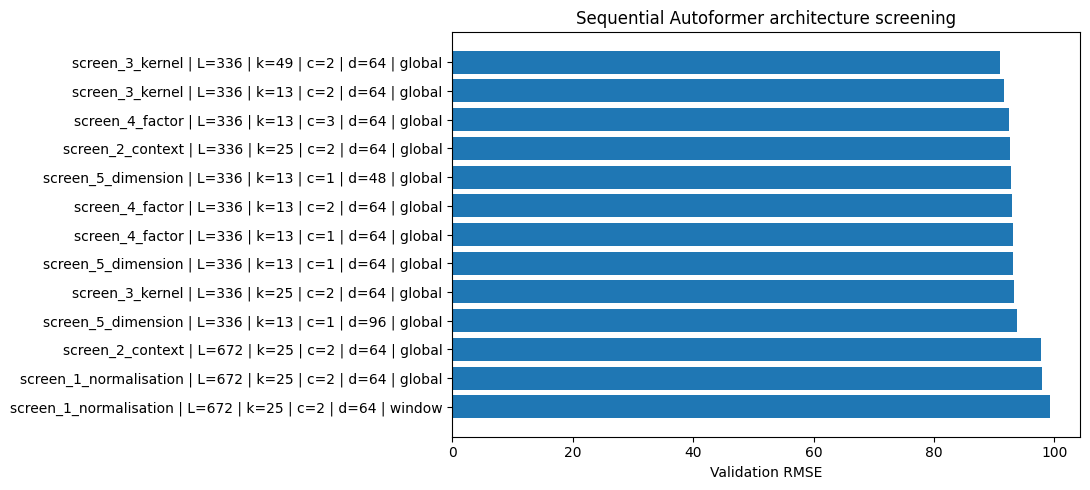

In [33]:
screeningplotframe = screeningresults.copy()
screeningplotframe["label"] = (
    screeningplotframe["stage"]
    + " | L=" + screeningplotframe["sequence_length"].astype(str)
    + " | k=" + screeningplotframe["moving_average_kernel"].astype(str)
    + " | c=" + screeningplotframe["factor"].astype(str)
    + " | d=" + screeningplotframe["model_dimension"].astype(str)
    + " | " + screeningplotframe["normalisation"]
)

figureheight = max(5, 0.38 * len(screeningplotframe))
figure, axis = plt.subplots(figsize=(11, figureheight))
orderedframe = screeningplotframe.sort_values("validation_rmse")
axis.barh(
    np.arange(len(orderedframe)),
    orderedframe["validation_rmse"].to_numpy()
)
axis.set_yticks(np.arange(len(orderedframe)))
axis.set_yticklabels(orderedframe["label"].tolist())
axis.invert_yaxis()
axis.set_xlabel("Validation RMSE")
axis.set_title("Sequential Autoformer architecture screening")
figure.tight_layout()
figure.savefig(
    resultsdirectory / "Q2_Figure_2_architecture_screening.pdf",
    bbox_inches="tight"
)
plt.show()

## Ablation Study

In [34]:
ablationrecords = []
ablationruns = []

for useexternal in [False, True]:
    for seed in finalseeds:
        print()
        print("External variables:", useexternal, "Seed:", seed)
        result = fitconfiguration(
            selectedconfiguration,
            seed=seed,
            useexternal=useexternal,
            trainingstride=finaltrainingstride,
            validationblockcount=validationblocks,
            maxepochs=finalmaxepochs,
            patience=finalpatience
        )
        ablationruns.append(result)
        ablationrecords.append(resultrow(result, "external_ablation"))
        pd.DataFrame(ablationrecords).to_csv(
            resultsdirectory / "external_ablation_runs.csv",
            index=False
        )

ablationframe = pd.DataFrame(ablationrecords)
display(ablationframe.round(5))

ablationsummary = (
    ablationframe
    .groupby("use_external")
    .agg(
        mean_rmse=("validation_rmse", "mean"),
        std_rmse=("validation_rmse", "std"),
        mean_mae=("validation_mae", "mean"),
        std_mae=("validation_mae", "std"),
        mean_smape=("validation_smape", "mean"),
        std_smape=("validation_smape", "std"),
        parameters=("parameters", "first"),
        median_best_epoch=("best_epoch", "median")
    )
    .reset_index()
)

ablationsummary.to_csv(
    resultsdirectory / "external_ablation_summary.csv",
    index=False
)

display(ablationsummary.round(5))

selectedexternal = bool(
    ablationsummary.sort_values("mean_rmse").iloc[0]["use_external"]
)

print("Selected use of external variables:", selectedexternal)


External variables: False Seed: 17


/tmp/ipykernel_48/1112870867.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)
/tmp/ipykernel_48/1112870867.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):
/tmp/ipykernel_48/185629505.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):


seed=17 external=False epoch=1 loss=1.099964 rmse=115.075202 mae=95.132389 smape=102.150
seed=17 external=False epoch=2 loss=1.078149 rmse=115.077392 mae=95.313105 smape=102.180
seed=17 external=False epoch=3 loss=1.073445 rmse=115.696131 mae=96.254001 smape=102.379
seed=17 external=False epoch=4 loss=1.067955 rmse=116.359029 mae=97.324408 smape=102.342

External variables: False Seed: 29
seed=29 external=False epoch=1 loss=1.095388 rmse=115.389617 mae=95.652408 smape=102.090
seed=29 external=False epoch=2 loss=1.076768 rmse=115.460097 mae=94.719847 smape=102.429
seed=29 external=False epoch=3 loss=1.074480 rmse=114.970722 mae=93.769371 smape=101.434
seed=29 external=False epoch=4 loss=1.068042 rmse=115.099076 mae=95.255735 smape=101.030
seed=29 external=False epoch=5 loss=1.062215 rmse=116.950859 mae=97.039517 smape=100.777
seed=29 external=False epoch=6 loss=1.057652 rmse=118.108737 mae=97.712026 smape=100.620

External variables: False Seed: 43
seed=43 external=False epoch=1 loss=1.

,stage,seed,use_external,normalisation,sequence_length,moving_average_kernel,factor,model_dimension,heads,encoder_layers,decoder_layers,feedforward_dimension,dropout,validation_rmse,validation_mae,validation_smape,parameters,best_epoch,epochs_run,fit_seconds
0,external_ablation,17,False,global,336,13,1,48,4,2,1,96,0.1,115.07520,95.13239,102.14968,66385,1,4,63.77788
1,external_ablation,29,False,global,336,13,1,48,4,2,1,96,0.1,114.97072,93.76937,101.43445,66385,3,6,96.45388
2,external_ablation,43,False,global,336,13,1,48,4,2,1,96,0.1,114.43899,93.98746,101.79304,66385,2,5,80.29136
3,external_ablation,17,True,global,336,13,1,48,4,2,1,96,0.1,72.02990,55.21988,75.24884,69265,6,9,155.79072
4,external_ablation,29,True,global,336,13,1,48,4,2,1,96,0.1,73.18901,58.17961,76.88048,69265,3,6,104.04675
5,external_ablation,43,True,global,336,13,1,48,4,2,1,96,0.1,75.77359,53.46389,70.64168,69265,6,9,152.88280


,use_external,mean_rmse,std_rmse,mean_mae,std_mae,mean_smape,std_smape,parameters,median_best_epoch
0,False,114.82830,0.34118,94.29641,0.73215,101.79239,0.35762,66385,2.0
1,True,73.66417,1.91654,55.62113,2.38333,74.25700,3.23550,69265,6.0


Selected use of external variables: True


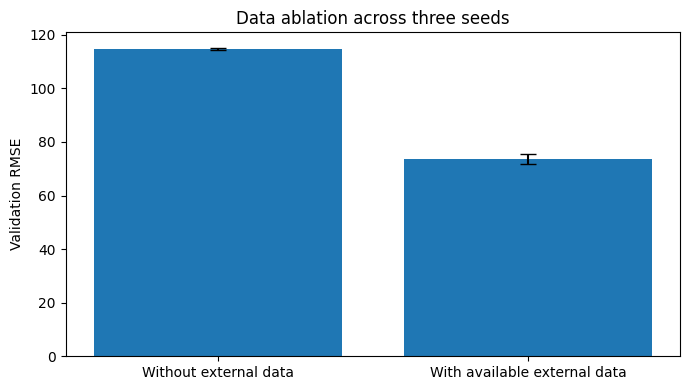

In [43]:
figure, axis = plt.subplots(figsize=(7, 4))
ablationlabels = [
    "Without external data" if not value else "With available external data"
    for value in ablationsummary["use_external"]
]
axis.bar(
    ablationlabels,
    ablationsummary["mean_rmse"],
    yerr=ablationsummary["std_rmse"],
    capsize=6
)
axis.set_ylabel("Validation RMSE")
axis.set_title("Data ablation across three seeds")
figure.tight_layout()
figure.savefig(
    resultsdirectory / "data_ablation.pdf",
    bbox_inches="tight"
)
plt.show()

## Best validation run

,origin,rmse,mae,smape
0,42816,87.11142,62.21803,46.33662
1,42984,55.15512,42.73414,77.35931
2,43152,91.61046,78.01185,91.47175
3,43320,71.87350,60.13250,93.09320
4,43488,41.86611,33.00286,67.98331


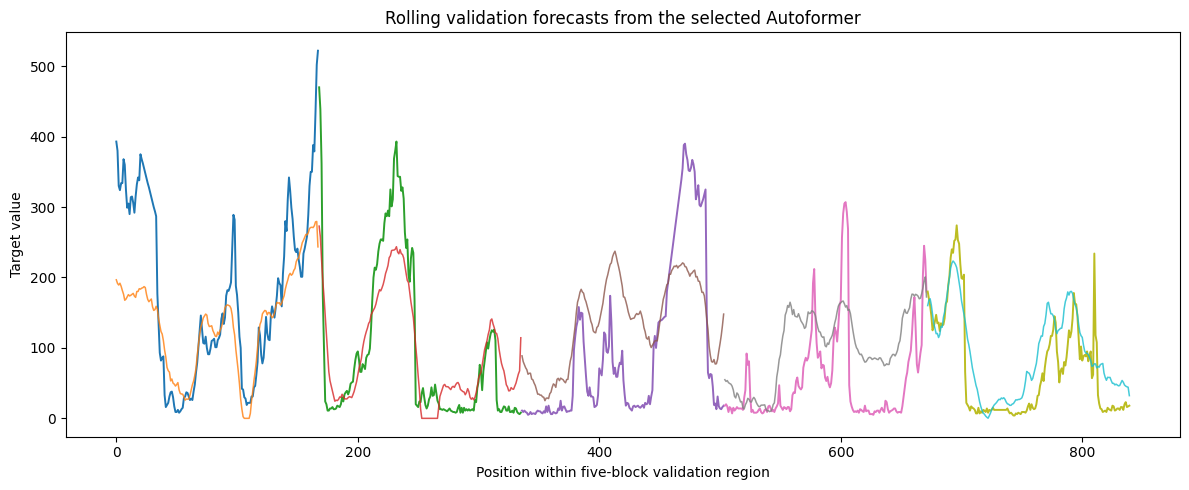

In [36]:
selectedablationruns = [
    result
    for result in ablationruns
    if result["useexternal"] == selectedexternal
]
bestvalidationrun = min(
    selectedablationruns,
    key=lambda result: result["validationrmse"]
)

bestblockmetrics = bestvalidationrun["blockmetrics"].copy()
display(bestblockmetrics.round(5))

bestactualvalues = bestvalidationrun["actualvalues"]
bestpredictedvalues = bestvalidationrun["predictedvalues"]

figure, axis = plt.subplots(figsize=(12, 5))
for blockindex in range(len(bestactualvalues)):
    plotstart = blockindex * predictionlength
    plotpositions = np.arange(
        plotstart,
        plotstart + predictionlength
    )
    axis.plot(
        plotpositions,
        bestactualvalues[blockindex],
        linewidth=1.4
    )
    axis.plot(
        plotpositions,
        bestpredictedvalues[blockindex],
        linewidth=1.1,
        alpha=0.8
    )
axis.set_xlabel("Position within five-block validation region")
axis.set_ylabel("Target value")
axis.set_title("Rolling validation forecasts from the Autoformer")
figure.tight_layout()
figure.savefig(
    resultsdirectory / "Q2_Figure_4_rolling_validation_forecasts.pdf",
    bbox_inches="tight"
)
plt.show()

## Delay diagnostic

In [37]:
bestmodel = bestvalidationrun["model"]
bestmodel.eval()
bestdatasets = bestvalidationrun["datasets"]
diagnosticdataset = bestdatasets["validationdataset"]
diagnosticbatch = diagnosticdataset[-1]

diagnosticencodercontext = diagnosticbatch["encodercontext"].unsqueeze(0).to(device)
diagnosticexternalhistory = diagnosticbatch["externalhistory"].unsqueeze(0).to(device)
diagnosticexternalfuture = diagnosticbatch["externalfuture"].unsqueeze(0).to(device)

with torch.no_grad():
    _ = bestmodel(
        diagnosticencodercontext,
        diagnosticexternalhistory,
        diagnosticexternalfuture
    )

encoderdelaymodule = bestmodel.encoder.layers[-1].autocorrelation.autocorrelation
selecteddelays = encoderdelaymodule.lastselecteddelays.squeeze(0).cpu().numpy()

delayframe = pd.DataFrame({
    "selected_delay": selecteddelays.astype(int)
})
delayframe.to_csv(
    resultsdirectory / "selected_encoder_delays.csv",
    index=False
)
display(delayframe)

,selected_delay
0,176
1,175
2,160
3,280
4,177


## Final full-history refit

In [38]:
selectedsummaryrow = ablationsummary[
    ablationsummary["use_external"] == selectedexternal
].iloc[0]

refitepochs = max(1, int(round(selectedsummaryrow["median_best_epoch"])))
selectedvalidationepochs = int(bestvalidationrun["bestepoch"])
declaredepochs = selectedvalidationepochs + refitepochs

setrandomseed(bestvalidationrun["seed"])

fulldatasets = builddatasets(
    selectedconfiguration,
    selectedexternal,
    finaltrainingstride,
    validationblocks,
    fulltraining=True
)

fulltrainingloader = DataLoader(
    fulldatasets["trainingdataset"],
    batch_size=batchsize,
    shuffle=True,
    num_workers=0,
    pin_memory=device.type == "cuda",
    drop_last=False
)

finalexternaldimension = len(externalcolumns) if selectedexternal else 0
finalmodel = buildmodel(
    selectedconfiguration,
    finalexternaldimension
).to(device)

finaloptimizer = torch.optim.Adam(
    finalmodel.parameters(),
    lr=learningrate,
    weight_decay=weightdecay
)
finalscaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)
finaltraininghistory = []

for epochnumber in range(1, refitepochs + 1):
    finalmodel.train()
    runningloss = 0.0
    processedbatches = 0

    for batch in fulltrainingloader:
        encodercontext = batch["encodercontext"].to(device, non_blocking=True)
        externalhistory = batch["externalhistory"].to(device, non_blocking=True)
        externalfuture = batch["externalfuture"].to(device, non_blocking=True)
        targetfuture = batch["targetfuture"].to(device, non_blocking=True)

        finaloptimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=usemixedprecision):
            normalisedforecast = finalmodel(
                encodercontext,
                externalhistory,
                externalfuture
            )
            loss = F.mse_loss(normalisedforecast, targetfuture)

        finalscaler.scale(loss).backward()
        finalscaler.unscale_(finaloptimizer)
        torch.nn.utils.clip_grad_norm_(finalmodel.parameters(), gradientclip)
        finalscaler.step(finaloptimizer)
        finalscaler.update()

        runningloss += float(loss.detach().cpu())
        processedbatches += 1

    meantrainingloss = runningloss / max(processedbatches, 1)
    finaltraininghistory.append({
        "epoch": epochnumber,
        "training_loss": meantrainingloss
    })
    print(
        f"Final refit epoch={epochnumber}/{refitepochs} "
        f"loss={meantrainingloss:.6f}"
    )

finalparametercount = counttrainableparameters(finalmodel)

torch.save({
    "model_state_dict": finalmodel.state_dict(),
    "configuration": selectedconfiguration,
    "use_external": selectedexternal,
    "external_columns": externalcolumns,
    "external_scaler": fulldatasets["externalscaler"],
    "global_mean": fulldatasets["globalmean"],
    "global_standard_deviation": fulldatasets["globalstandarddeviation"],
    "seed": bestvalidationrun["seed"],
    "refit_epochs": refitepochs,
    "selected_validation_epochs": selectedvalidationepochs,
    "declared_epochs": declaredepochs,
    "parameter_count": finalparametercount
}, resultsdirectory / "final_autoformer.pt")

pd.DataFrame(finaltraininghistory).to_csv(
    resultsdirectory / "final_training_history.csv",
    index=False
)

print("Final parameter count:", finalparametercount)
print("Selected validation epochs:", selectedvalidationepochs)
print("Full-history refit epochs:", refitepochs)
print("Declared epochs:", declaredepochs)

/tmp/ipykernel_48/4025873657.py:39: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  finalscaler = torch.cuda.amp.GradScaler(enabled=usemixedprecision)
/tmp/ipykernel_48/4025873657.py:55: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=usemixedprecision):


Final refit epoch=1/6 loss=0.869381
Final refit epoch=2/6 loss=0.721819
Final refit epoch=3/6 loss=0.668923
Final refit epoch=4/6 loss=0.638944
Final refit epoch=5/6 loss=0.616324
Final refit epoch=6/6 loss=0.599116
Final parameter count: 69265
Selected validation epochs: 6
Full-history refit epochs: 6
Declared epochs: 12


## Leaderboard Forecast

In [44]:
finalsequencelength = selectedconfiguration["sequencelength"]
finalcontextvalues = targetvalues[-finalsequencelength:]

finallocation, finalscale = targetstatistics(
    finalcontextvalues,
    selectedconfiguration["normalisationmode"],
    fulldatasets["globalmean"],
    fulldatasets["globalstandarddeviation"]
)

normalisedfinalcontext = (
    (finalcontextvalues - finallocation) / finalscale
).astype(np.float32)

if selectedexternal:
    transformedfullexternal = transformexternalvalues(
        externalvalues,
        fulldatasets["externalscaler"]
    )
    finalexternalhistory = transformedfullexternal[
        len(targetvalues) - finalsequencelength:len(targetvalues)
    ].astype(np.float32)
    finalexternalfuture = transformedfullexternal[
        len(targetvalues):len(targetvalues) + predictionlength
    ].astype(np.float32)
else:
    finalexternalhistory = np.zeros(
        (finalsequencelength, 0),
        dtype=np.float32
    )
    finalexternalfuture = np.zeros(
        (predictionlength, 0),
        dtype=np.float32
    )

finalmodel.eval()

with torch.no_grad():
    finalnormalisedforecast = finalmodel(
        torch.from_numpy(normalisedfinalcontext[:, None]).unsqueeze(0).to(device),
        torch.from_numpy(finalexternalhistory).unsqueeze(0).to(device),
        torch.from_numpy(finalexternalfuture).unsqueeze(0).to(device)
    )

finalforecast = (
    finalnormalisedforecast.squeeze(0).squeeze(-1).float().cpu().numpy()
    * finalscale
    + finallocation
)

finalforecast = np.maximum(finalforecast, 0.0)

if len(finalforecast) != predictionlength:
    raise RuntimeError(
        f"Expected {predictionlength} forecasts, produced {len(finalforecast)}"
    )

predictionframe = pd.DataFrame({
    "time_idx": testingtimeindices,
    "prediction": finalforecast
})

predictionframe.to_csv(
    resultsdirectory / "final_predictions.csv",
    index=False
)

leaderboardstring = ", ".join(
    f"{forecastvalue:.10g}"
    for forecastvalue in finalforecast
)

(resultsdirectory / "leaderboard_predictions.txt").write_text(
    leaderboardstring,
    encoding="utf-8"
)

print("Forecast count:", len(finalforecast))
print("Parameters:", finalparametercount)
print("Epochs:", declaredepochs)
print()
print(leaderboardstring)

Forecast count: 168
Parameters: 69265
Epochs: 12

23.6436615, 21.93676758, 24.78124237, 26.3481369, 30.48522949, 30.91092682, 30.23673248, 35.20257187, 35.78560638, 35.74391556, 38.86468506, 43.83987045, 47.49276733, 50.26441956, 55.35776901, 55.10005569, 54.80353165, 55.25646591, 60.07907486, 61.56032181, 73.25054169, 76.80619812, 84.86048889, 90.59655762, 92.7768631, 93.06211853, 95.40407562, 102.5201035, 107.2355347, 116.1488037, 125.2773209, 133.5170135, 142.8631134, 154.5315552, 158.2549438, 157.9211731, 160.1483765, 166.1292267, 172.9979248, 178.453598, 182.1143951, 185.2613068, 187.5867004, 188.1399841, 184.6897888, 178.0076599, 174.5347595, 176.4747925, 175.6311035, 160.3314514, 154.1606293, 153.7254639, 154.8302917, 151.8786621, 143.5357208, 140.2915802, 137.742691, 139.7067413, 147.3361816, 154.561554, 156.2274017, 159.1382294, 169.3677216, 176.0864105, 174.0804901, 173.9145203, 182.8588104, 190.1522217, 202.7431793, 208.3193665, 203.7610168, 192.7281342, 180.1500092, 171.449

## Final forecast figure

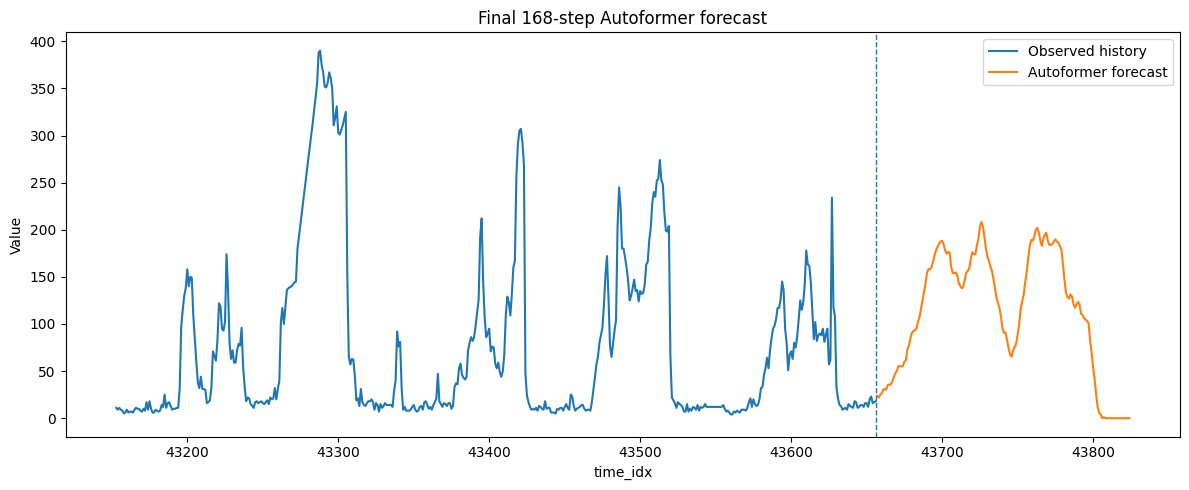

In [40]:
displayhistorylength = min(504, len(targetvalues))
historystartposition = len(targetvalues) - displayhistorylength
historypositions = trainingtimeindices[-displayhistorylength:]
forecastpositions = testingtimeindices

figure, axis = plt.subplots(figsize=(12, 5))
axis.plot(
    historypositions,
    targetvalues[-displayhistorylength:],
    label="Observed history"
)
axis.plot(
    forecastpositions,
    finalforecast,
    label="Autoformer forecast"
)
axis.axvline(
    trainingtimeindices[-1],
    linewidth=1,
    linestyle="--"
)
axis.set_xlabel("time_idx")
axis.set_ylabel("Value")
axis.set_title("Final 168-step Autoformer forecast")
axis.legend()
figure.tight_layout()
figure.savefig(
    resultsdirectory / "Q2_Figure_5_final_forecast.pdf",
    bbox_inches="tight"
)
plt.show()